# Patient visits: before vs after treatment

**What this is.** An exploration, not part of the analysis pipeline. Three patients were recorded twice, with a treatment between the two visits: how does their arm movement differ between the first visit (**pre**) and the second (**post**)? Healthy participants are drawn in grey as a reference.

**For looking only:** no statistical tests (3 patients, one session per visit). A difference between pre and post can come from the treatment, but also from the day, the recording setup or how the trials were run (see the assumptions below).

**How it is organised**
- **Two settings choose what to look at:** `TASKS` (one task, or several) and `PATIENTS` (by default the 3 patients with two visits).
- **Sections 1-3, what the data is:** the visits used, the healthy reference, the trials available per task.
- **Sections 4-6, the comparison:** pre vs post at a glance (4), the movement over time (5), every repetition (6).

**Colours:** pre = blue, post = orange, healthy = grey (median line and 25-75 % band). A thin line or a point = one trial (one repetition of the movement); a thick line or a black bar = the mean or median. Panels that compare arms or visits always share the same y axis.

**Arms:** for stroke patients, **contralesional** (the arm opposite the brain lesion, usually the affected one) and **ipsilesional**, once `lesion_side` (the hemisphere of the lesion) is filled in `data/participants.csv`; for the other patients, **affected** / **less affected** once `affected_side` is filled; otherwise **left** / **right**. Healthy participants: always left / right.

## The data and what is measured

Patients and healthy participants do 8 arm tasks (listed in section 3) in a room where a markerless camera system tracks the body in 3D. Each task is repeated about 10 times with each arm; one repetition = one **trial**. The pipeline of the repo (notebooks `01_preprocess`, `02_movement_table`, `03_cut_movement`, one folder up):
1. organises the recordings into sessions, trials and frames, and flags the doubtful trials;
2. puts each trial on a regular time grid, filters it, and expresses the elbow and wrist positions **from the shoulder, in the person's own directions** (forward = in front of the chest, out = to the side, up = up; the left arm is mirrored so both arms are comparable);
3. cuts each trial to the movement itself (from when the wrist starts moving to when it stops).

**Numbers measured here** (code: `measures.py`):

| number | what it says |
|---|---|
| shoulder elevation (degrees) | angle between the upper arm and straight down: 0 = arm hanging, 90 = horizontal, 180 = straight up |
| elbow angle (degrees) | angle at the elbow between upper arm and forearm: 180 = straight arm |
| movement duration (s) | from the start to the end of the movement (step 3) |
| shoulder range (degrees) | largest − smallest shoulder elevation in the trial: how far the arm goes up |
| largest elbow angle (degrees) | how straight the arm gets in the trial |
| shoulder-elbow coupling | correlation between shoulder elevation and elbow angle over the trial: +1 = the elbow opens while the arm goes up, −1 = it bends, 0 = no link |

The smoothness of the movement (jerk) is computed in `measures.py` but **not shown**: it depends on the camera frame rate, which changed between the visits (see below).

**Trials used:** only those that pass the quality checks of step 1 (goal reached, normal end, camera on the right person, enough frames), and without repetition 1 (practice trial). Both can be changed in the settings.

## Who can be compared, and what is assumed

**Only DBB (stroke), MAM (CBD) and JFR (PSP) can be compared:** they are the only patients with two visits. MFC, FCG, ISA and LSR were assessed once (no reassessment yet). If they come back, add their new sessions to `data/session_participant.csv` with `visit = 2` and they can be compared too.

**Assumptions, to be confirmed by Luana** (the physiotherapist who recorded the sessions; asked by email on 28/10/2026; written in `data/session_participant.csv`):
- **DBB pre** (29/06): the recordings at 10:44 and 10:47, no ID typed. Luana's time: 10:30.
- **MAM pre** (29/06): the recordings at 12:37, 12:40 and 12:51, no ID typed. Luana's time: 12:30.
- **MAM post** (11/08): the recording typed "MBM" at 17:09 is MAM. Luana's time: 16:00.
- **JFR pre** (10/07): the recordings from 15:24 to 15:34, no ID typed. **UNSURE:** Luana says 17:30, and nothing was recorded after 15:34 that day.
- **JFR post** (14/09): the recording typed "004" at 11:36 is JFR (same date and hour as Luana's reassessment).
- **Healthy reference:** see the next cell.

**Differences between the visits that do not come from the patient:**
- **Camera frame rate:** all 3 patients were filmed at about 17-19 frames per second pre and about 33 post. This is why the smoothness (jerk) is not shown.
- **How the trials were ended:** almost all automatically before 02/09, all by the operator after (every session, patients included). DBB and MAM: both visits before 02/09 (same). JFR: pre automatic, post by the operator.

Section 1 shows all this per recording, from the data.

## The healthy reference (grey in the plots)

- **Who:** the 16 sessions labelled healthy: the 15 sessions recorded **without an ID** (29/06 morning, 06/07, 08/07, 10/07) and "anon" (29/07). We do not know who they are (asked to Luana): several sessions may be the same person, and most look like members of the team testing the setup. Each session counts as one "person".
- **Only the right arm**, filmed at about 17-19 frames per second, all trials ended automatically.
- **Per task:** 2 to 10 sessions, 17 to 182 trials (section 2). Tasks 7 and 8 have only 2 sessions.
- **How it is drawn:** same trial selection as the patients. For each task, the median and the 25-75 % band over all the healthy trials (curves: at each point of the movement; numbers: over the trials).

So: a **rough reference**, not a norm. Proper healthy recordings (both arms, ID typed, full protocol) are still needed.

In [1]:
%load_ext autoreload
%autoreload 2
import sys

import pandas as pd

sys.path.insert(0, "..")   # the code (measures.py, ...) is in the repo folder, one level up
import measures

## What is known about the patients
From `data/participants.csv` (filled by hand). **No patient has `affected_side` or `lesion_side` yet** (empty = not known), so all arms are shown as left / right. The recordings do not contain it (the operator only typed the dominant arm in some sessions): it has to come from the clinical team.

In [2]:
from config import PARTICIPANTS_CSV

participants = pd.read_csv(PARTICIPANTS_CSV, dtype=str)
participants[participants["condition"] != "healthy"][["participant_id", "condition", "affected_side", "lesion_side"]]

,participant_id,condition,affected_side,lesion_side
0,DBB,Stroke,NaN,NaN
1,MAM,CBD,NaN,NaN
2,JFR,PSP,NaN,NaN
3,MFC,MSA-C,NaN,NaN
4,FCG,SCA3,NaN,NaN
5,ISA,Stroke,NaN,NaN
6,LSR,Parkinson,NaN,NaN


## Settings: what to look at
**`TASKS`** and **`PATIENTS`** choose what sections 1 and 4-6 show. Most of the time: one task, the 3 patients. Change a value, then re-run from here.

In [3]:
TASKS = [2]                        # one task, e.g. [2]; several, e.g. [1, 2, 8]; all: [1, 2, 3, 4, 5, 6, 7, 8]
PATIENTS = ["DBB", "MAM", "JFR"]   # participant_id; DBB, MAM, JFR have 2 visits (pre, post);
                                   # MFC, FCG, ISA, LSR have 1 (only that visit is shown)

## Settings: how to look at it
The trial selection, the healthy reference, and the two normalization switches. The normalizations only change the curves (section 5); they can be used separately or together.

In [4]:
TIME_NORMALIZE = True         # True = every movement on the same time axis, 0-100 % of the movement
N_POINTS = 200                # points per movement when TIME_NORMALIZE is True
SIZE_NORMALIZE = False        # True = positions divided by the arm length (angles do not change)
ONLY_PASSING_TRIALS = True    # keep only trials with passes_checks
SKIP_FIRST_REPETITION = True  # leave out repetition 1 (practice trial)
SHOW_HEALTHY = True           # draw the healthy participants as a grey reference

In [5]:
# The settings collected for the functions.
settings = {"time_normalize": TIME_NORMALIZE, "n_points": N_POINTS, "size_normalize": SIZE_NORMALIZE,
            "only_passing_trials": ONLY_PASSING_TRIALS, "skip_first_repetition": SKIP_FIRST_REPETITION}

movement_cut, info = measures.load_data()
moments = measures.add_angles(movement_cut)               # the 2 angles at every moment
per_trial = measures.trial_measures(moments, info)        # one row per trial: the numbers of the table above
selected = measures.select_trials(per_trial, settings)    # the trials used (settings)

patients = measures.patient_trials(selected, PATIENTS, TASKS)       # the chosen patients, in the chosen tasks
healthy = measures.healthy_trials(selected, TASKS, SHOW_HEALTHY)    # the healthy reference, in the chosen tasks
curve_table = measures.curves(moments, pd.concat([patients, healthy]), measures.WRIST + measures.ANGLES, settings)
measures.describe_choice(info, PATIENTS, TASKS)

DBB (Stroke): visits pre, post
MAM (CBD): visits pre, post
JFR (PSP): visits pre, post
Task 2 (Shoulder abduction with elbow extended)


## 1. The visits used
One row per recording of the chosen patients: which visit, when it was recorded, the ID typed during the recording (`(none)` = no ID typed), the number of trials (kept by step 3, all tasks), the camera frame rate, how many trials were ended by the operator, and the notes of `session_participant.csv` (the assignments made by hand, to be confirmed).

In [6]:
measures.visits_table(info, PATIENTS)

,person,condition,visit_label,recorded,trials,frames_per_second,ended_by_operator_pct,typed_id,notes
0,DBB,Stroke,pre,29/06 10:47,289,17.0,10.0,(none),no ID typed; matched with Luana's date and hou...
1,DBB,Stroke,post,10/08 11:22,284,33.2,13.0,DBB,
2,JFR,PSP,pre,10/07 15:24,12,18.8,92.0,(none),UNSURE: no ID typed; Luana says 17:30 but noth...
3,JFR,PSP,pre,10/07 15:31,20,18.8,95.0,(none),UNSURE: no ID typed; Luana says 17:30 but noth...
4,JFR,PSP,pre,10/07 15:34,224,18.7,2.0,(none),UNSURE: no ID typed; Luana says 17:30 but noth...
5,JFR,PSP,post,14/09 11:36,265,32.8,100.0,004,"typed 004, corrected to JFR (same date and hou..."
6,MAM,CBD,pre,29/06 12:40,72,17.6,0.0,(none),no ID typed; matched with Luana's date and hou...
7,MAM,CBD,pre,29/06 12:51,192,17.3,1.0,(none),no ID typed; matched with Luana's date and hou...
8,MAM,CBD,post,11/08 17:09,270,33.2,3.0,MBM,"typed MBM, corrected to MAM (Luana says 16:00,..."


## 2. The healthy reference, per task
What the grey reference is made of, per task (after the same trial selection as the patients). All 8 tasks are shown, to help choose `TASKS`.

In [7]:
measures.healthy_overview(measures.healthy_trials(selected))

,,trials,sessions,right_arm,left_arm,frames_per_second,ended_by_operator_pct
task_id,task_name,,,,,,
1,Shoulder flexion with elbow extended,58,6,58,0,18.0,0.0
2,Shoulder abduction with elbow extended,31,3,31,0,17.9,0.0
3,Draw a 5 segment trajectory,24,4,24,0,17.6,0.0
4,Reaching different targets,59,3,59,0,18.9,0.0
5,Draw a circle,29,4,29,0,18.1,0.0
6,Horizontal reaching,182,10,182,0,17.6,0.0
7,Drinking test: reaching glass to mouth,20,2,20,0,16.7,0.0
8,Index to nose,17,2,17,0,17.2,0.0


## 3. Trials available per task
Trials per task, patient and visit (after the trial selection). All 8 tasks are shown, to help choose `TASKS`: DBB, MAM and JFR have both visits in every task. Each task is done with both arms (about half of the trials each); tasks 4 and 6 have several targets, so more trials.

In [8]:
measures.trials_per_task(measures.patient_trials(selected, PATIENTS))

person                                         DBB      JFR      MAM     
visit                                          pre post pre post pre post
task_id task_name                                                        
1       Shoulder flexion with elbow extended    22   22  21   22  22   22
2       Shoulder abduction with elbow extended  33   22  16   22  22   26
3       Draw a 5 segment trajectory             18   22  21   21  22   22
4       Reaching different targets              69   58  58   58  58   58
5       Draw a circle                           20   22  22   22  21   16
6       Horizontal reaching                     58   65  58   58  58   58
7       Drinking test: reaching glass to mouth  20   22  18   22  21   21
8       Index to nose                           22   25  22   22  22   22

## 4. Pre vs post at a glance
For a few numbers: one panel per task of `TASKS`, the **median** over the trials of each patient and arm at pre and at post, joined by a line. Colour and marker = patient; dashed line = contralesional, affected or left arm; solid line = ipsilesional, less affected or right arm (see **Arms** at the top). Grey: the healthy median and 25-75 % band of the task. A line going up = the number is higher at post.

Choose the numbers in the cell.

**Reading tip:** if the patients all change in the same direction in a task, think of what changed between the visits for everyone (camera rate, recording period, how the trials were ended) before thinking of the treatment.

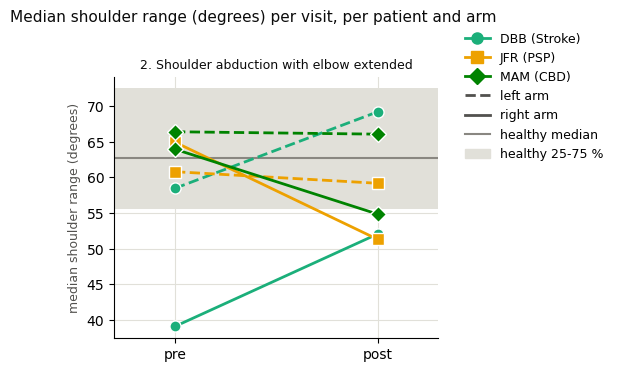

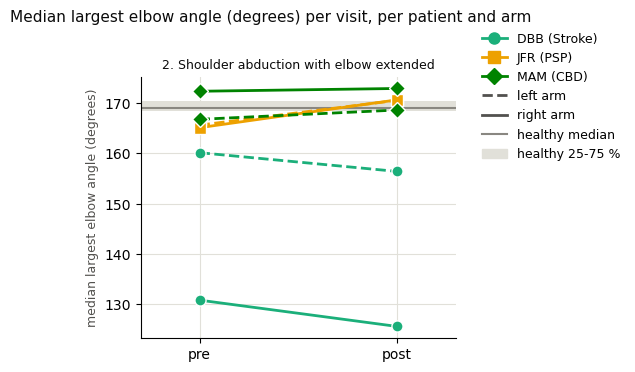

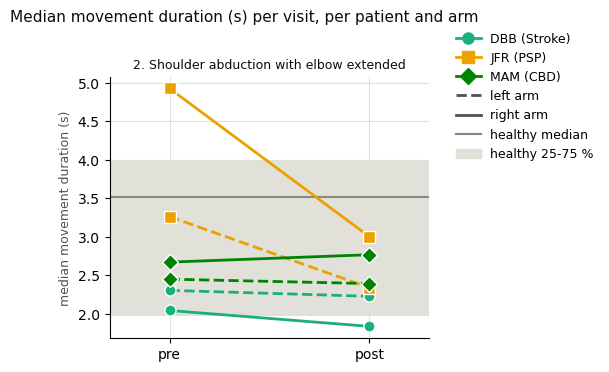

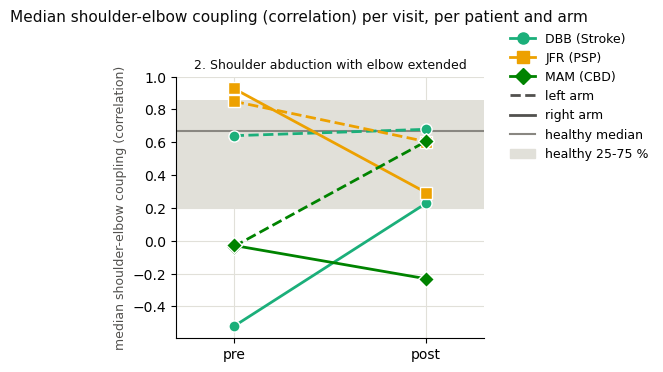

In [9]:
NUMBERS_AT_A_GLANCE = ["shoulder_range_deg", "max_elbow_angle_deg", "movement_duration_s", "coupling_r"]

for number in NUMBERS_AT_A_GLANCE:
    measures.plot_visits_all_tasks(per_trial, patients, healthy, number)

## 5. Movement over time
For each task of `TASKS`: one row per patient, one panel per arm. Every repetition as a thin line, the mean as a thick line, **pre in blue, post in orange**. Grey: healthy participants (median and 25-75 % band). Same y scale in every panel.

x axis: % of the movement (`TIME_NORMALIZE = True`) or seconds since the movement start (`False`: then the mean is drawn only where at least half of the trials are still going). Choose what to draw in the cell (the wrist positions are in metres, or in arm lengths with `SIZE_NORMALIZE = True`).

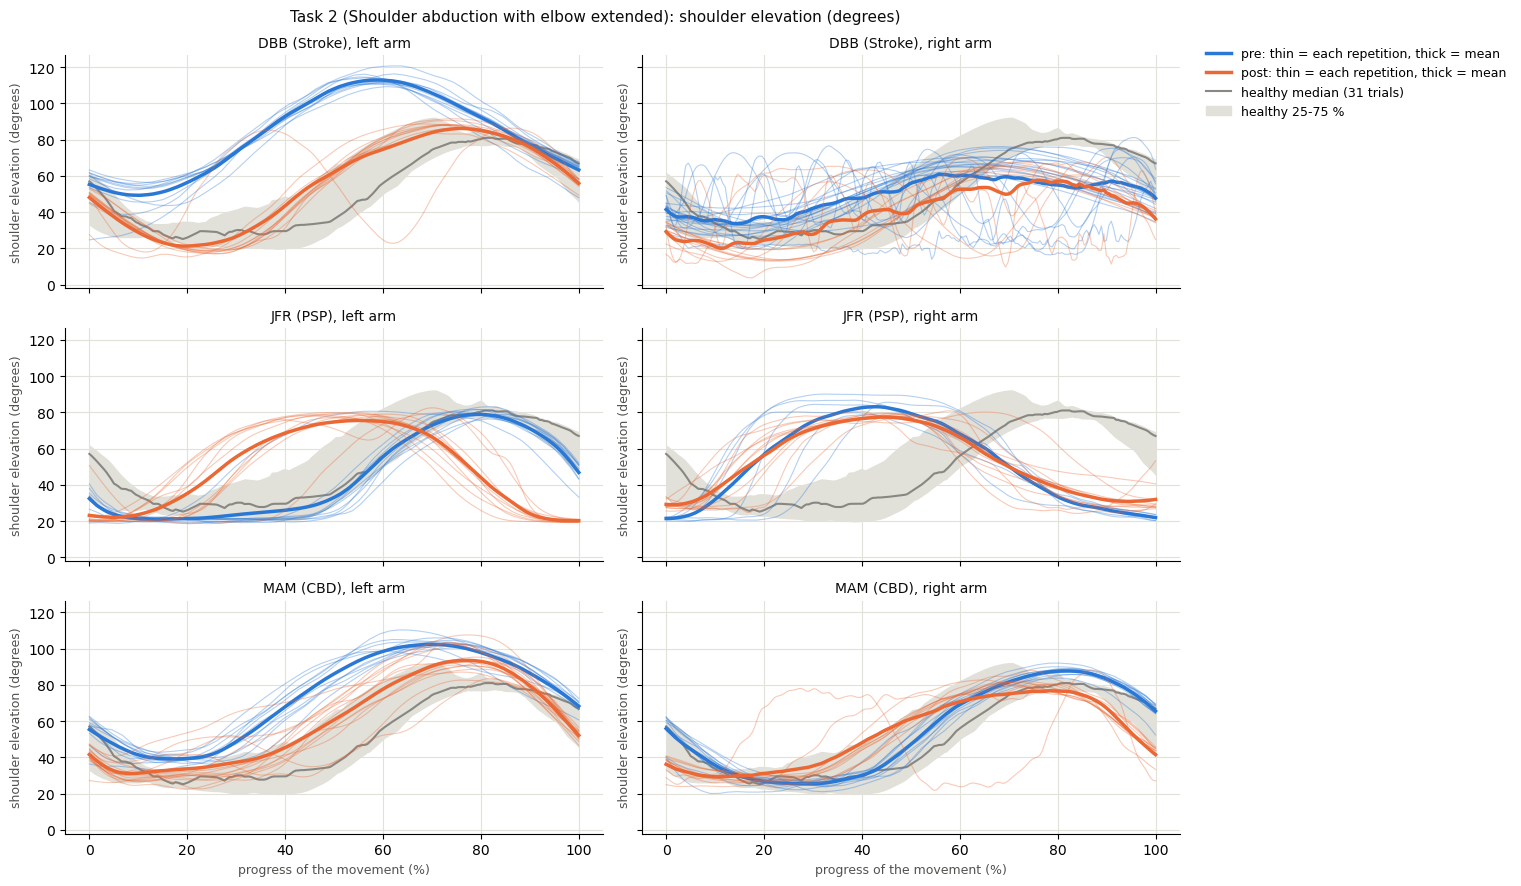

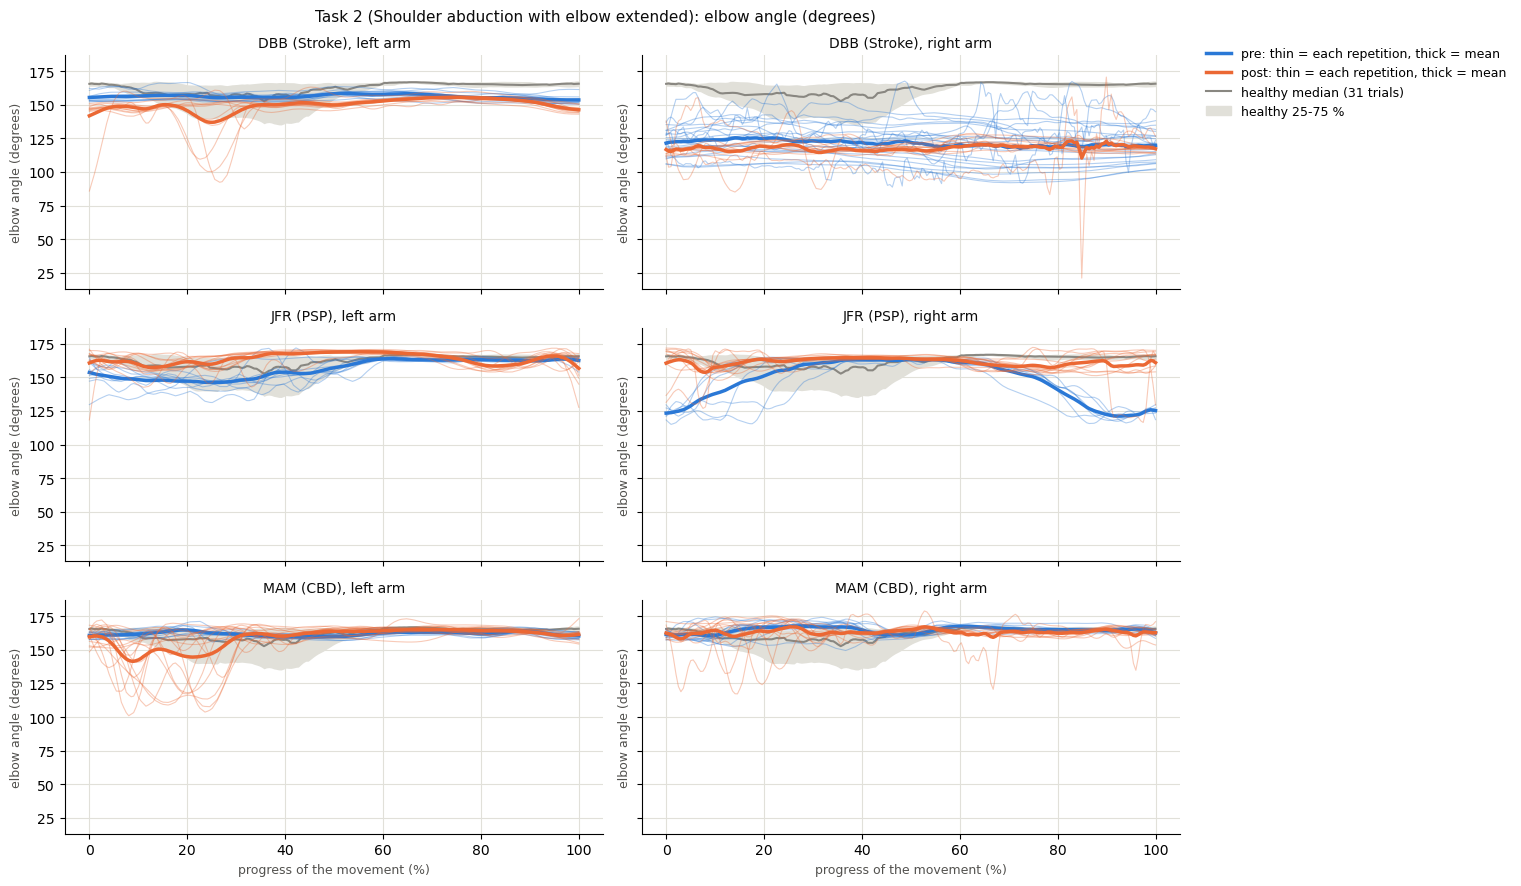

In [10]:
CURVES = ["shoulder_elevation_deg", "elbow_angle_deg"]   # any of: wrist_up, wrist_forward, wrist_out,
                                                         # shoulder_elevation_deg, elbow_angle_deg
for task_id in TASKS:
    for column in CURVES:
        measures.plot_curves_patients(curve_table, measures.of_task(patients, task_id),
                                      measures.of_task(healthy, task_id)["trial_id"], column, settings,
                                      measures.task_title(info, task_id))

## 6. Every repetition
The same numbers as in section 4, but **every repetition as a point** instead of only the median. It shows whether a pre/post difference is bigger than the normal variation from one repetition to the next:
- pre and post points clearly apart → the change seen in section 4 is real for that patient;
- pre and post points mixed → the difference of the medians in section 4 may just be noise.

For each task of `TASKS`: one row per number, one column per patient. In each panel, for each arm: pre (blue), post (orange), then the healthy trials (grey). Black bar = median. Same y scale along a row.

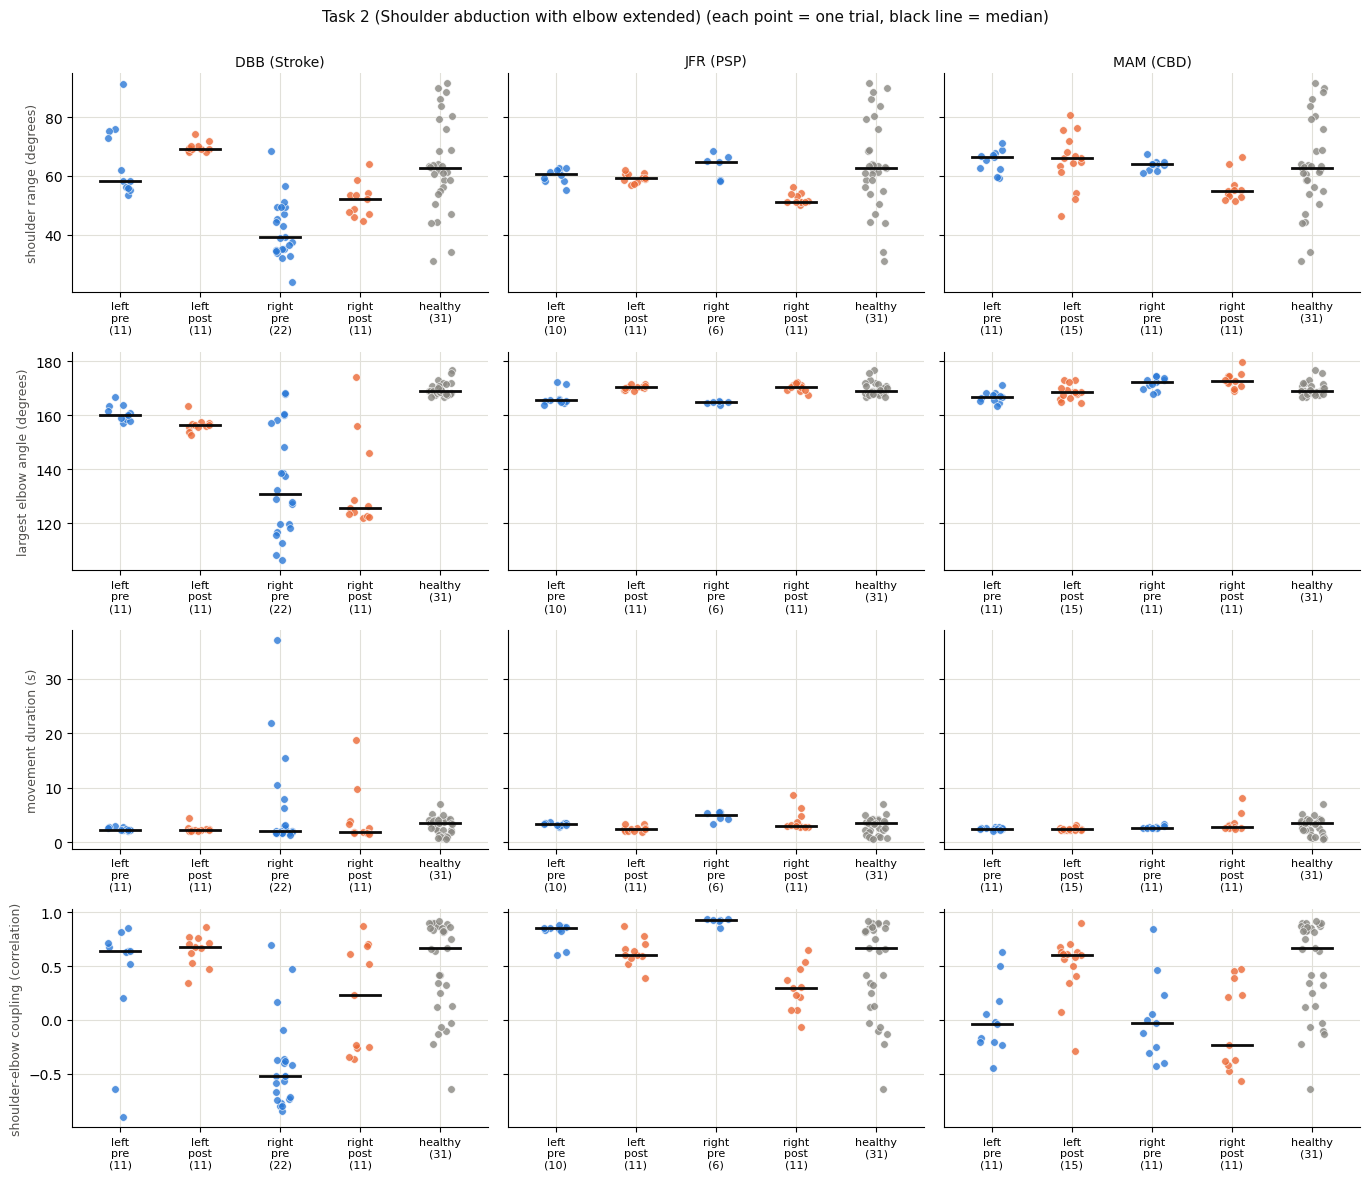

In [11]:
NUMBERS = ["shoulder_range_deg", "max_elbow_angle_deg", "movement_duration_s", "coupling_r"]

for task_id in TASKS:
    measures.plot_measures_patients(per_trial, measures.of_task(patients, task_id),
                                    measures.of_task(healthy, task_id)["trial_id"], NUMBERS,
                                    measures.task_title(info, task_id))